# Observed and virtual tissue

Extract one annotated sample from `data/backup_output.rds` and generate the same number of cells in the same rectangular domain. Compare the observed and generated cell composition and spatial organization.

Install the package with `pip install -e '.[notebook]'` from the repo root using a Python 3.11+ kernel environment. Reading the full archive uses about 6 GB of RAM. The extraction keeps only the selected sample after reading.

In [1]:
%matplotlib inline

from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdata
from IPython.display import display
from rdata.parser import RObjectType

from tissue_generation import cell_composition, funcn_matrix, generate_from_summary, summarize

archive_candidates = (Path("data/backup_output.rds"), Path("../data/backup_output.rds"))
archive = next((path for path in archive_candidates if path.is_file()), None)
if archive is None:
    raise FileNotFoundError("Open this notebook from the repository root or notebooks folder.")

SAMPLE_ID = None  # Use the smallest sample, or enter a sample ID.
LABEL_FIELD = "cell_clustering1m"  # Use "cell_clustering2m" for finer annotations.
STATISTIC = "mean"  # Also accepts "median".
PERMUTATIONS = 19  # Used by median FunCN.
SIGMA = None  # Derive from average spacing, or enter a width in native coordinate units.
STEPS = 3000
SEED = 42

## Extract one sample

The archive stores centroid coordinates as `X_position` and `Y_position` in the `fcs1` flow frames. The separate clustering vector follows per-sample cell order. The loader checks the sample blocks against the archive metadata, checks frame row counts, and checks that the centroid frame's `CellId` values match the corresponding `fcs` frame in row order. It retains every cell in the selected sample, including the archive's `UA` category when present.

[rdata parsing API](https://rdata.readthedocs.io/en/stable/apilist.html)

In [2]:
def dereference(obj):
    while obj.info.type == RObjectType.REF:
        obj = obj.referenced_object
    return obj


def r_text(obj):
    obj = dereference(obj)
    if obj.info.type == RObjectType.SYM:
        obj = dereference(obj.value)
    return obj.value.decode("utf-8") if obj.value is not None else None


def r_pairs(node):
    while node is not None:
        node = dereference(node)
        if node.info.type in (RObjectType.NIL, RObjectType.NILVALUE):
            break
        value, tail = node.value
        yield r_text(node.tag), dereference(value)
        node = tail


def r_fields(obj):
    fields = dict(r_pairs(obj.attributes))
    names = (r_text(label) for label in fields["names"].value)
    return dict(zip(names, map(dereference, obj.value), strict=True))


def flow_frame_columns(flow_set, frame_name, columns):
    frames = dict(r_pairs(flow_set.attributes))["frames"].value
    frame_index = dict(r_pairs(frames.frame))
    if frames.hash_table.info.type == RObjectType.VEC:
        for bucket in frames.hash_table.value:
            frame_index.update(r_pairs(bucket))
    exprs = dict(r_pairs(frame_index[frame_name].attributes))["exprs"]
    attributes = dict(r_pairs(exprs.attributes))
    names = [r_text(label) for label in dereference(attributes["dimnames"].value[1]).value]
    matrix = exprs.value.reshape(attributes["dim"].value, order="F")
    return matrix[:, [names.index(column) for column in columns]]


def load_sample(path, sample_id, label_field):
    root = r_fields(rdata.parser.parse_file(path).object)
    fields = r_fields(root["meta_data"])
    metadata = pd.DataFrame({
        name: rdata.conversion.convert(fields[name])
        for name in ("file_name", "sample_id", "File_order")
    })
    metadata["File_order"] = metadata["File_order"].astype(int)
    metadata = metadata.sort_values("File_order")
    cell_sample_ids = root["sample_ids"].value
    labels = root[label_field].value
    block_ids = cell_sample_ids[np.r_[True, cell_sample_ids[1:] != cell_sample_ids[:-1]]]
    if len(cell_sample_ids) != len(labels) or not np.array_equal(block_ids, metadata["sample_id"]):
        raise ValueError("Cell annotations do not match the archive's sample blocks.")

    sample_sizes = pd.Series(cell_sample_ids).value_counts().sort_index()
    chosen = int(sample_sizes.idxmin() if sample_id is None else sample_id)
    match = metadata.loc[metadata["sample_id"] == chosen]
    if len(match) != 1:
        raise ValueError(f"Unknown or ambiguous sample ID {chosen}.")
    sample = match.iloc[0]
    indices = np.flatnonzero(cell_sample_ids == chosen)

    xy_ids = flow_frame_columns(
        root["fcs1"], f"V{sample.File_order}", ("X_position", "Y_position", "CellId")
    )
    original_ids = flow_frame_columns(root["fcs"], sample.file_name, ("CellId",))
    if len(xy_ids) != len(indices) or len(original_ids) != len(indices):
        raise ValueError("Coordinates and labels have different row counts.")
    np.testing.assert_allclose(xy_ids[:, 2], original_ids[:, 0], rtol=1e-6, atol=1e-8)
    cells = pd.DataFrame(xy_ids[:, :2], columns=["x", "y"])
    cells["cell_type"] = [r_text(labels[index]) for index in indices]
    if not np.isfinite(cells[["x", "y"]]).all().all() or cells["cell_type"].isna().any():
        raise ValueError("The selected sample contains missing coordinates or labels.")
    return chosen, cells, len(sample_sizes)

In [3]:
sample_id, observed, n_samples = load_sample(archive, SAMPLE_ID, LABEL_FIELD)
axes_cols = ["x", "y"]
observed[axes_cols] = observed[axes_cols] - observed[axes_cols].min()
domain_size = tuple(observed[axes_cols].max().to_numpy())
x_size, y_size = domain_size
n_cells = len(observed)
sigma = SIGMA if SIGMA is not None else 2 * np.sqrt(x_size * y_size / n_cells)
types = sorted(observed["cell_type"].unique())
palette = plt.get_cmap("tab20")
colors = {label: palette(index / max(1, len(types) - 1)) for index, label in enumerate(types)}

print(f"Sample {sample_id} of {n_samples} samples · {n_cells:,} cells · {len(types)} types")
print(f"Domain {x_size:.2f} × {y_size:.2f} · FunCN sigma {sigma:.2f} (native coordinate units)")

Sample 40 of 64 samples · 357 cells · 5 types
Domain 955.95 × 129.58 · FunCN sigma 37.25 (native coordinate units)


The observed centroids are translated to an origin of zero. Their bounding rectangle defines the domain for both tissues. Sigma defaults to twice the square root of area per cell. The generator can place cells anywhere inside those bounds.

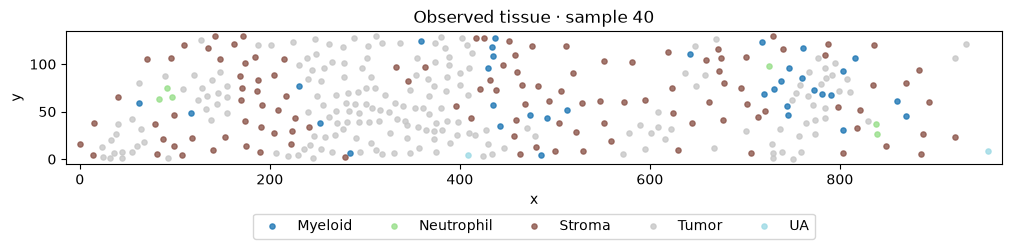

In [4]:
def plot_cells(ax, cells, title):
    for label in types:
        group = cells[cells["cell_type"] == label]
        ax.scatter(group["x"], group["y"], s=14, color=colors[label], label=label, alpha=0.8)
    ax.set(
        title=title, xlabel="x", ylabel="y",
        xlim=(-0.015 * x_size, 1.015 * x_size),
        ylim=(-0.04 * y_size, 1.04 * y_size),
        aspect="equal",
    )


fig, ax = plt.subplots(figsize=(10, 3.5), layout="constrained")
plot_cells(ax, observed, f"Observed tissue · sample {sample_id}")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncols=min(len(types), 6))
plt.show()

## Generate the matched tissue

Use the observed counts, area, and FunCN targets to generate a continuous-space tissue. Both panels use the same axis limits, scale, and type colors.

The energy plot shows the current placement and the best placement found so far. The generator returns the best placement.

Annealing: 100%|██████████| 3000/3000 [00:00<00:00, 10158.72proposal/s, current=0.01487, best=0.01482]


Generation finished in 0.307 s (annealing setup and search 0.305 s) · proposal budget reached
Energy 0.129248 → 0.0148196 (best at proposal 2,932, last 0.0148673)
Proposals 3,000/3,000 · accepted 2,195/2,461 evaluated (89.2%) · skipped 539 · target pairs 25


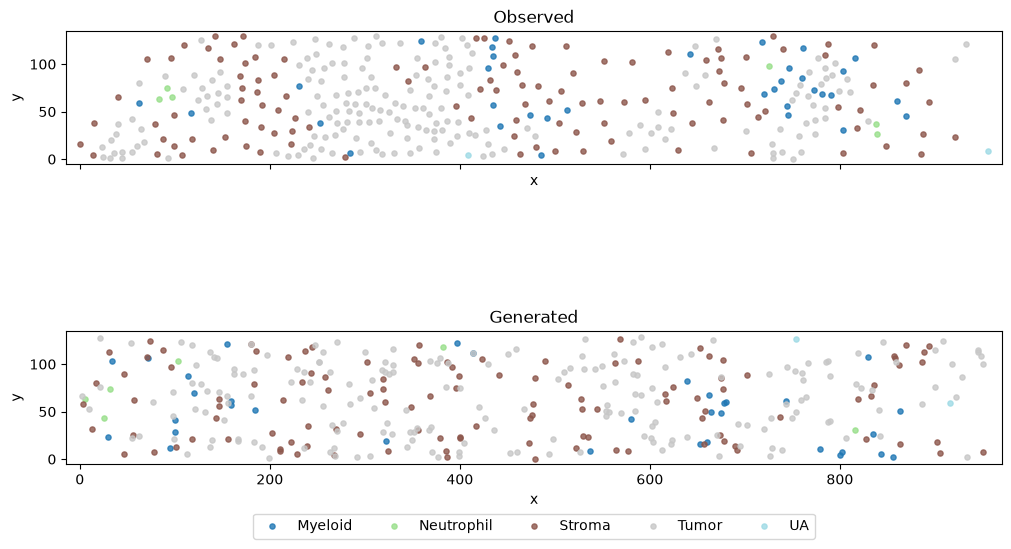

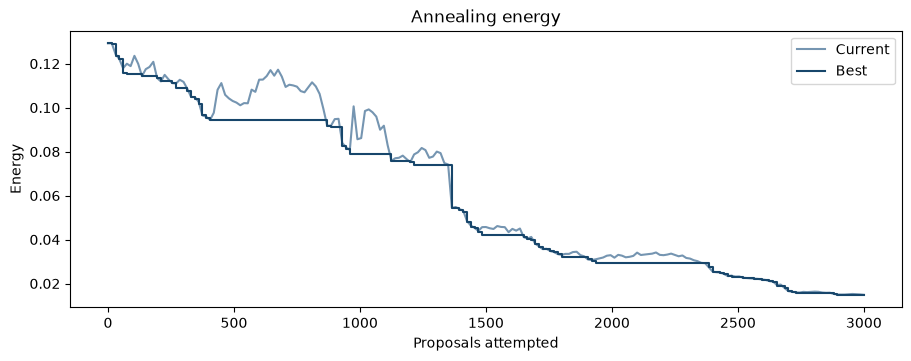

In [5]:
metric = dict(sigma=sigma, statistic=STATISTIC, permutations=PERMUTATIONS, seed=SEED)
targets = summarize(observed, reference_size=domain_size, **metric)
virtual = generate_from_summary(
    targets, domain_size=domain_size, n_cells=n_cells, steps=STEPS, seed=SEED,
    progress=True,
)
assert len(virtual) == n_cells
assert ((virtual[axes_cols] >= 0) & (virtual[axes_cols] < domain_size)).all().all()

fig, axes = plt.subplots(2, 1, figsize=(10, 6), sharex=True, sharey=True, layout="constrained")
plot_cells(axes[0], observed, "Observed")
plot_cells(axes[1], virtual, "Generated")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncols=min(len(types), 6))
plt.show()

history = pd.DataFrame(
    virtual.attrs["annealing"]["energy_history"],
    columns=["proposal", "current", "best"],
)
if len(history) > 1:
    fig, ax = plt.subplots(figsize=(9, 3.5), layout="constrained")
    ax.plot(history["proposal"], history["current"], color="#7595b1", label="Current")
    ax.step(history["proposal"], history["best"], where="post", color="#17466b", label="Best")
    ax.set(xlabel="Proposals attempted", ylabel="Energy", title="Annealing energy")
    ax.legend()
    plt.show()

## Compare cell composition and spatial organization

Cell counts and densities use the same rectangular area. The generator allocates the same composition at this cell count, so matching composition is a check of the generation setup. FunCN is independently measured on each cell table. A ratio of 1 is the random-labeling baseline, and undefined pairs are shown in gray. The error is calculated only for pairs defined in both tissues.

In [6]:
observed_composition = cell_composition(observed, reference_size=domain_size)
virtual_composition = cell_composition(virtual, reference_size=domain_size)
pd.testing.assert_frame_equal(observed_composition, virtual_composition)
composition = pd.concat({"Observed": observed_composition, "Generated": virtual_composition}, axis=1)
formats = {"count": "{:,}", "abundance": "{:.1%}", "density": "{:.5g}"}
display(composition.style.format({column: formats[column[1]] for column in composition.columns}))

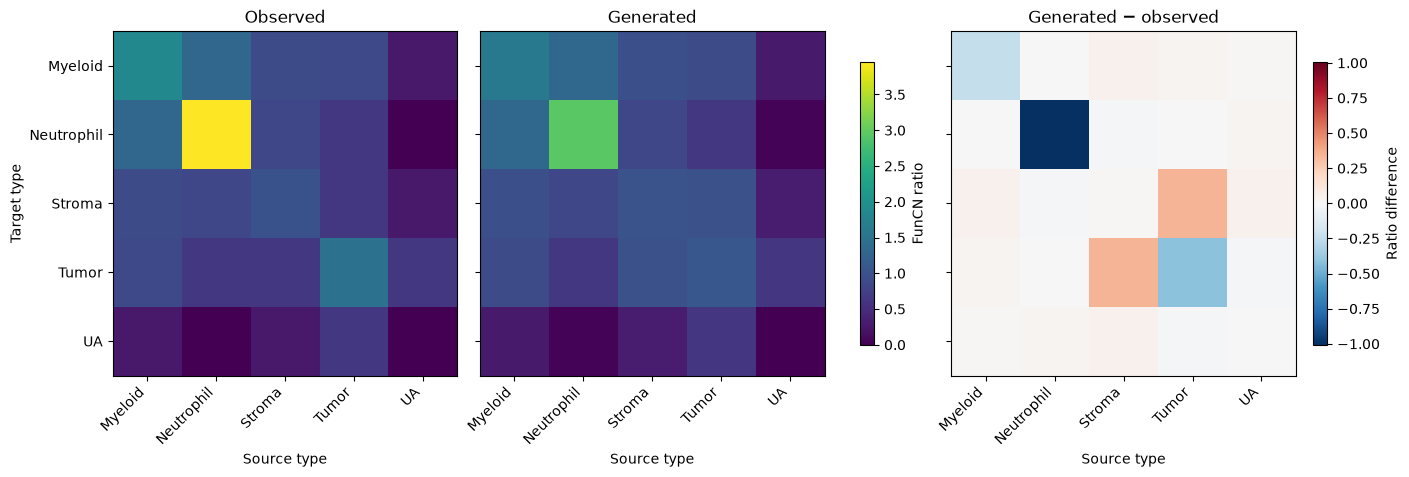

Comparable ordered pairs: 25 / 25
Mean absolute FunCN error: 0.1093


observed  generated  difference
target     source                                     
Neutrophil Neutrophil    3.9559     2.9491     -1.0068
Tumor      Tumor         1.4941     1.0783     -0.4159
           Stroma        0.6433     0.9851      0.3419
Stroma     Tumor         0.6433     0.9851      0.3419
Myeloid    Myeloid       1.8488     1.6053     -0.2435
Stroma     Myeloid       0.9215     0.9636      0.0421
Myeloid    Stroma        0.9215     0.9636      0.0421
UA         Stroma        0.2662     0.3062      0.0400
Stroma     UA            0.2662     0.3062      0.0400
Myeloid    Tumor         0.8751     0.9059      0.0307

In [7]:
observed_funcn = funcn_matrix(observed, **metric).reindex(index=types, columns=types)
virtual_funcn = funcn_matrix(virtual, **metric).reindex(index=types, columns=types)
delta = virtual_funcn - observed_funcn
valid = delta.stack().dropna()
maximum = max(1, observed_funcn.max().max(), virtual_funcn.max().max())
difference_limit = max(float(valid.abs().max()), 1e-9) if len(valid) else 1
sequential = plt.get_cmap("viridis").with_extremes(bad="#dedede")
diverging = plt.get_cmap("RdBu_r").with_extremes(bad="#dedede")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True, layout="constrained")
for ax, matrix, title, cmap, limits in (
    (axes[0], observed_funcn, "Observed", sequential, (0, maximum)),
    (axes[1], virtual_funcn, "Generated", sequential, (0, maximum)),
    (axes[2], delta, "Generated − observed", diverging, (-difference_limit, difference_limit)),
):
    image = ax.imshow(matrix, cmap=cmap, vmin=limits[0], vmax=limits[1])
    ax.set_title(title)
    ax.set_xticks(range(len(types)), types, rotation=45, ha="right")
    ax.set_yticks(range(len(types)), types)
    ax.set_xlabel("Source type")
    if ax is axes[1]:
        fig.colorbar(image, ax=axes[:2], shrink=0.77, label="FunCN ratio")
    if ax is axes[2]:
        fig.colorbar(image, ax=ax, shrink=0.77, label="Ratio difference")
axes[0].set_ylabel("Target type")
plt.show()

if len(valid):
    print(f"Comparable ordered pairs: {len(valid)} / {delta.size}")
    print(f"Mean absolute FunCN error: {valid.abs().mean():.4f}")
    pair_comparison = pd.DataFrame({
        "observed": observed_funcn.stack(),
        "generated": virtual_funcn.stack(),
        "difference": valid,
    }).dropna().rename_axis(index=["target", "source"])
    display(pair_comparison.sort_values("difference", key=lambda values: values.abs(),
                                       ascending=False).head(10).round(4))
else:
    print("No FunCN ratios were defined for both tissues.")